# Does solve_rate learn the easy-to-hard transition over training?

**Question.** `spin_gnn.train_sudoku_transformer`'s `solve_rate` on the training-time
`rho` range (`[0.3, 0.95]`, mixing shallow and deep reasoning chains) collapsed to
`0.005` by epoch 50 (see `STATUS.md`) -- but that single number averages over every
difficulty at once. Does the model actually learn the easy (high `rho`, shallow,
few deduction rounds) end of that range while still failing the hard (low `rho`,
deep) end, or is it uniformly bad everywhere?

**Method.** `spin_gnn.sudoku_transition_sweep` trains once, snapshotting the model
at several epochs, then re-evaluates `solve_rate` separately at each of several fixed
(pinned, not ranged) `rho` values for every snapshot -- `spin_gnn.
train_sudoku_transformer.eval_solve_by_rho`. Each line below is one checkpoint; the
x-axis is the evaluation `rho` (high/easy on the left, low/hard on the right, same
orientation as `notebooks/results_transition.ipynb`).

**Data provenance.** Initial sweep (rho up to 0.95): training+eval `48144619`, notebook
render `48145554`. Extended sweep (rho up to 1.0, the fully trivial all-hinted case):
training+eval `48146991`, notebook render `48150261`.

**Finding.** The *shape* is confirmed: epochs 0-20 are flat at `solve_rate=0.00` across
every `rho`, and epochs 30-50 rise *only* at the high-`rho` (easy/shallow) end while
staying at `0.00` for `rho<=0.8`.

Extending the grid to `rho=0.97/0.99/1.0` (the last being the fully trivial,
zero-reasoning-round, all-hints-given case) shows this is *not* a difficulty-curve-
positioning problem: `solve_rate` plateaus around `0.28-0.34` even at `rho=1.0`, it
never approaches ~1.0. Crucially, `outcome_accuracy` and `well_formed_rate` are *already*
saturated at `1.0` across the whole `rho>=0.9` range at epoch 50 -- the model reliably
produces well-formed output and always calls SOLVED/UNRESOLVED correctly, but still gets
at least one of the 24 colors wrong in roughly two-thirds of even the most trivial
instances. That combination (saturated structural/outcome accuracy, capped exact-match
accuracy) points to a model-capacity/precision ceiling on exact 24-node copying, not a
difficulty-curve-positioning issue. The current `d_model=64`/2-layer/2000-instance/
50-epoch budget is the likely bottleneck, consistent with `STATUS.md`'s existing note
that this budget 'is nowhere near enough for this harder depth distribution' -- scaling
up model size and/or training length is the natural next step to actually reach a ~100%
easy-end plateau.

In [1]:
import glob
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

INK = {"surface": "#fcfcfb", "primary": "#0b0b0b", "secondary": "#52514e",
       "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7"}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams["font.family"] = "sans-serif"


def style_axis(ax):
    ax.set_facecolor(INK["surface"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(INK["axis"])
    ax.spines["bottom"].set_color(INK["axis"])
    ax.tick_params(colors=INK["muted"])
    ax.grid(True, color=INK["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.title.set_color(INK["primary"])


RESULTS_DIR = Path(os.environ["SCRATCH"]) / "spin_gnn" / "sudoku_transition"

# Most recent sweep CSV by mtime -- one row per (epoch, rho).
csv_path = max(glob.glob(str(RESULTS_DIR / "sweep_*.csv")), key=os.path.getmtime)
df = pd.read_csv(csv_path)
print(f"loaded {csv_path}: {len(df)} rows, epochs={sorted(df['epoch'].unique())}")
df.head()

loaded /scratch/users/hshunt/spin_gnn/sudoku_transition/sweep_48146991.csv: 77 rows, epochs=[0, 5, 10, 20, 30, 40, 50]


,epoch,rho,solve_rate,outcome_accuracy,well_formed_rate,n_instances
0,0,0.3,0.0,0.0,0.0,50
1,0,0.4,0.0,0.0,0.0,50
2,0,0.5,0.0,0.0,0.0,50
3,0,0.6,0.0,0.0,0.0,50
4,0,0.7,0.0,0.0,0.0,50


## Key plot: solve_rate vs. rho, one line per checkpoint epoch

Expectation: early checkpoints flat and low everywhere. Later checkpoints rise toward
the easy (high-`rho`, left) end while staying low on the hard (low-`rho`, right) end --
i.e. the model learns the shallow regime first, matching the aggregate `solve_rate`
collapse being driven by the hard end, not uniform failure.

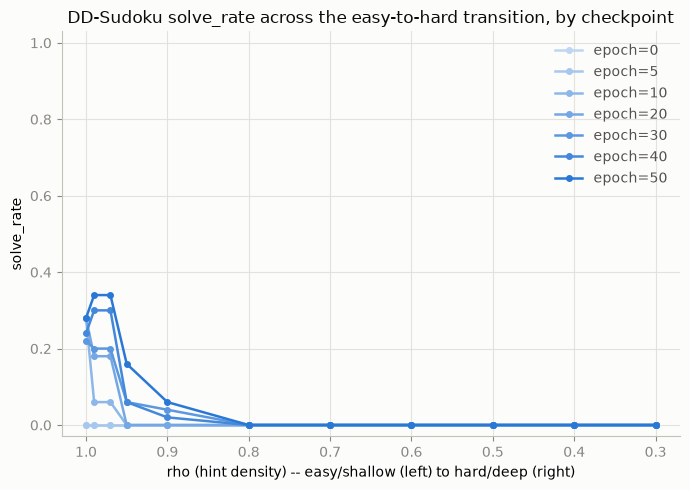

In [2]:
fig, ax = plt.subplots(figsize=(7, 5))
fig.patch.set_facecolor(INK["surface"])

epochs = sorted(df["epoch"].unique())
shades = np.linspace(0.3, 1.0, len(epochs))
for epoch, shade in zip(epochs, shades):
    sub = df[df["epoch"] == epoch].sort_values("rho")
    color = tuple(np.array(plt.matplotlib.colors.to_rgb(CATEGORICAL[0])) * shade +
                  np.array([1, 1, 1]) * (1 - shade))
    ax.plot(sub["rho"], sub["solve_rate"], color=color, lw=1.8, marker="o", ms=4, label=f"epoch={epoch}")

ax.set_xlim(df["rho"].max() + 0.03, df["rho"].min() - 0.03)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel("rho (hint density) -- easy/shallow (left) to hard/deep (right)")
ax.set_ylabel("solve_rate")
ax.set_title("DD-Sudoku solve_rate across the easy-to-hard transition, by checkpoint")
style_axis(ax)
ax.legend(frameon=False, labelcolor=INK["secondary"])
fig.tight_layout()
fig.savefig(RESULTS_DIR / "solve_rate_by_rho_and_epoch.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

In [3]:
df.pivot(index="epoch", columns="rho", values="solve_rate")

rho,0.30,0.40,0.50,0.60,0.70,0.80,0.90,0.95,0.97,0.99,1.00
epoch,,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00
5,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00
10,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.06,0.06,0.28
20,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.18,0.18,0.28
30,0.0,0.0,0.0,0.0,0.0,0.0,0.04,0.06,0.20,0.20,0.22
40,0.0,0.0,0.0,0.0,0.0,0.0,0.02,0.06,0.30,0.30,0.24
50,0.0,0.0,0.0,0.0,0.0,0.0,0.06,0.16,0.34,0.34,0.28
